<a href="https://colab.research.google.com/github/dptel22/Nosh-Robotics/blob/main/Task_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Pull SAM 3 model

In [1]:
!git clone https://github.com/facebookresearch/sam3.git
!pip install -q -e ./sam3


Cloning into 'sam3'...
remote: Enumerating objects: 1502, done.
remote: Counting objects: 100% (54/54), done.
remote: Compressing objects: 100% (43/43), done.
remote: Total 1502 (delta 29), reused 11 (delta 11), pack-reused 1448 (from 3)
Receiving objects: 100% (1502/1502), 60.70 MiB | 33.76 MiB/s, done.
Resolving deltas: 100% (580/580), done.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Building editable for sam3 (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the 

#Hugging face login

In [2]:
from google.colab import userdata
from huggingface_hub import login
login(userdata.get("HF_TOKEN"))

#Check the environment

In [1]:
import sys
import numpy as np
import torch

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("NumPy test:", np.random.rand(3))

from sam3.model_builder import build_sam3_image_model
from sam3.model.sam3_image_processor import Sam3Processor

print("SAM 3 imports successful")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy: 1.26.4
PyTorch: 2.11.0+cu130
CUDA available: True
NumPy test: [0.25626237 0.94909413 0.08838732]


/content/sam3/sam3/model_builder.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/content/sam3/sam3/model/model_misc.py:71: UserWarning: Flash Attention is disabled as it requires a GPU with Ampere (8.0) CUDA capability.
  OLD_GPU, USE_FLASH_ATTN, MATH_KERNEL_ON = get_sdpa_settings()


SAM 3 imports successful


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


In [6]:
%pip install -q --force-reinstall "numpy>=1.26,<2"
%pip install -q -e /content/sam3

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.0.0, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 1.26.4 which is incompatible.
rasterio 1.5.2 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
tobler 0.14.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
pytensor 2.38.3 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
opencv-contrib-python 4.14.0.94 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
cupy-cuda13x 14.0.1 requires numpy<2.6,>=2.0, but you have numpy 1.26.4 which is incompatible.
opencv-python-headless 5.0.0.93 re

#Load the data

In [2]:
!unzip -q "/content/egg.v3i.folder.zip" -d /content/

In [3]:
from pathlib import Path

# Define the path to your extracted dataset
dataset_dir = Path("/content/egg.v3i.folder")

# Find all valid images deterministically (ignoring hidden/system files)
valid_extensions = {".jpg", ".jpeg", ".png", ".webp"}
all_images = sorted(
    p for p in dataset_dir.rglob("*")
    if p.is_file()
    and p.suffix.lower() in valid_extensions
    and not p.name.startswith(".")
    and "__MACOSX" not in p.parts
)

print(f"Dataset Folder: {dataset_dir.resolve()}")
print(f"Total Images Loaded: {len(all_images)}")
if all_images:
    print("Example Image Path:", all_images[0])
else:
    print("No images found. Please verify the unzip command executed fully.")

Dataset Folder: /content/egg.v3i.folder
Total Images Loaded: 160
Example Image Path: /content/egg.v3i.folder/test/egg/not_damaged_101_jpg.rf.38605ebedec1a67bbdfd051be8fcbf76.jpg


#Load SAM 3

In [4]:
import os
device = "cuda" if torch.cuda.is_available() else "cpu"

# Manually define the BPE vocabulary path to bypass the pkg_resources error
bpe_path = "/content/sam3/sam3/assets/bpe_simple_vocab_16e6.txt.gz"
if not os.path.exists(bpe_path):
    # fallback to local relative path if needed
    bpe_path = "sam3/sam3/assets/bpe_simple_vocab_16e6.txt.gz"

model = build_sam3_image_model(bpe_path=bpe_path, device=device)
model.eval()

processor = Sam3Processor(
    model,
    device=device,
    confidence_threshold=0.30,
)

print("SAM 3 loaded on:", device)

config.json:   0%|          | 0.00/25.8k [00:00<?, ?B/s]

sam3.pt: reconstructing file:   0%|          |  0.00B / 3.45GB            

sam3.pt: downloading bytes:           |  0.00B            

SAM 3 loaded on: cuda


# Define segmentation and mask processing

In [5]:
from PIL import Image, ImageDraw
import numpy as np
import torch

# Dynamically select safe AMP dtype based on GPU architecture (prevents T4 bfloat16 slowdown/errors)
USE_AMP = (device == "cuda")
AMP_DTYPE = (
    torch.bfloat16
    if (USE_AMP and torch.cuda.is_bf16_supported())
    else torch.float16
)


def select_masks_gpu(masks_tensor, scores_tensor, min_area=0.002, max_area=0.98, iou_threshold=0.70):
    """
    Vectorized Mask NMS executed directly on the GPU before CPU transfer.
    Returns indices of kept masks sorted by descending confidence score.
    """
    if masks_tensor.numel() == 0 or len(masks_tensor) == 0:
        return []

    if masks_tensor.ndim == 4:
        masks_tensor = masks_tensor[:, 0]  # (N, 1, H, W) -> (N, H, W)

    masks_bool = masks_tensor > 0
    N, H, W = masks_bool.shape
    total_pixels = float(H * W)

    # 1. Area filtering on GPU
    flat = masks_bool.reshape(N, -1).to(torch.float32)
    pixel_areas = flat.sum(dim=1)
    norm_areas = pixel_areas / total_pixels

    valid_mask = (norm_areas >= min_area) & (norm_areas <= max_area)
    valid_indices = torch.where(valid_mask)[0]
    if len(valid_indices) == 0:
        return []

    # 2. Sort valid candidates by descending score
    valid_scores = scores_tensor[valid_indices]
    sorted_order = torch.argsort(valid_scores, descending=True)
    ordered_indices = valid_indices[sorted_order]

    # 3. All-pairs IoU matrix via single GPU matrix multiplication
    flat_ordered = flat[ordered_indices]
    areas_ordered = pixel_areas[ordered_indices]

    intersections = flat_ordered @ flat_ordered.T
    unions = areas_ordered[:, None] + areas_ordered[None, :] - intersections
    iou_matrix = torch.where(unions > 0, intersections / unions, torch.zeros_like(unions))

    # 4. Greedy NMS suppression
    iou_cpu = iou_matrix.cpu().numpy()
    ordered_cpu = ordered_indices.cpu().tolist()

    kept = []
    suppressed = np.zeros(len(ordered_cpu), dtype=bool)
    for i in range(len(ordered_cpu)):
        if suppressed[i]:
            continue
        kept.append(ordered_cpu[i])
        suppressed[i + 1 :] |= iou_cpu[i, i + 1 :] > iou_threshold

    return kept


def segment_image(image_input):
    """
    Accepts either a file Path or a pre-loaded PIL.Image.
    Runs SAM 3 inference and GPU-accelerated Mask NMS.
    """
    if isinstance(image_input, (str, Path)):
        image = Image.open(image_input).convert("RGB")
    else:
        image = image_input

    with torch.inference_mode(), torch.autocast(device_type=device, dtype=AMP_DTYPE, enabled=USE_AMP):
        state = processor.set_image(image)
        result = processor.set_text_prompt(
            state=state,
            prompt="egg",
        )

        raw_masks = result["masks"].detach()
        if raw_masks.ndim == 4:
            raw_masks = raw_masks[:, 0]
        raw_scores = result["scores"].detach().float().reshape(-1)
        n_raw = int( len(raw_masks) )

        kept_raw_indices = select_masks_gpu(raw_masks, raw_scores)

        # Only transfer the surviving masks to CPU RAM!
        if kept_raw_indices:
            kept_masks = (raw_masks[kept_raw_indices] > 0).cpu().numpy()
            kept_scores = raw_scores[kept_raw_indices].cpu().numpy()
        else:
            H, W = image.size[1], image.size[0]
            kept_masks = np.zeros((0, H, W), dtype=bool)
            kept_scores = np.zeros((0,), dtype=np.float32)

    kept = list(range(len(kept_masks)))
    return image, kept_masks, kept_scores, kept, n_raw


def make_overlay(image, masks, scores, kept):
    """Colour the egg masks over the original image and annotate confidence scores."""
    result = np.asarray(image).copy()

    colours = [
        (255, 60, 60),
        (40, 220, 100),
        (40, 140, 255),
        (255, 190, 30),
        (210, 70, 255),
    ]

    label_positions = []

    for instance_id, i in enumerate(kept):
        mask = masks[i]
        if not mask.any():
            continue

        colour = np.array(colours[instance_id % len(colours)], dtype=np.uint8)

        result[mask] = (
            0.55 * result[mask] + 0.45 * colour
        ).astype(np.uint8)

        # Mark the mask boundary without requiring OpenCV
        eroded = np.zeros_like(mask)
        eroded[1:-1, 1:-1] = (
            mask[1:-1, 1:-1]
            & mask[:-2, 1:-1]
            & mask[2:, 1:-1]
            & mask[1:-1, :-2]
            & mask[1:-1, 2:]
        )
        result[mask & ~eroded] = colour

        # Find centroid for confidence score label
        ys, xs = np.where(mask)
        label_positions.append((int(xs.mean()), int(ys.mean()), float(scores[i]), tuple( int(c) for c in colour )))

    overlay_pil = Image.fromarray(result)
    draw = ImageDraw.Draw(overlay_pil)
    for cx, cy, score, col in label_positions:
        text = f"{score:.2f}"
        draw.rectangle([cx - 18, cy - 8, cx + 18, cy + 8], fill=(0, 0, 0))
        draw.text((cx - 14, cy - 6), text, fill=col)

    return overlay_pil

# Test on one image

Image: not_damaged_101_jpg.rf.38605ebedec1a67bbdfd051be8fcbf76.jpg
Raw detections: 1
Masks after duplicate removal: 1
Confidence scores: [0.969]


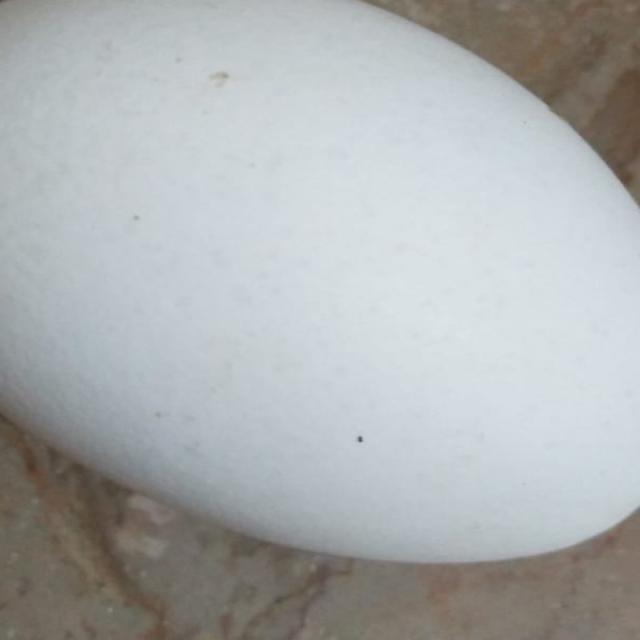

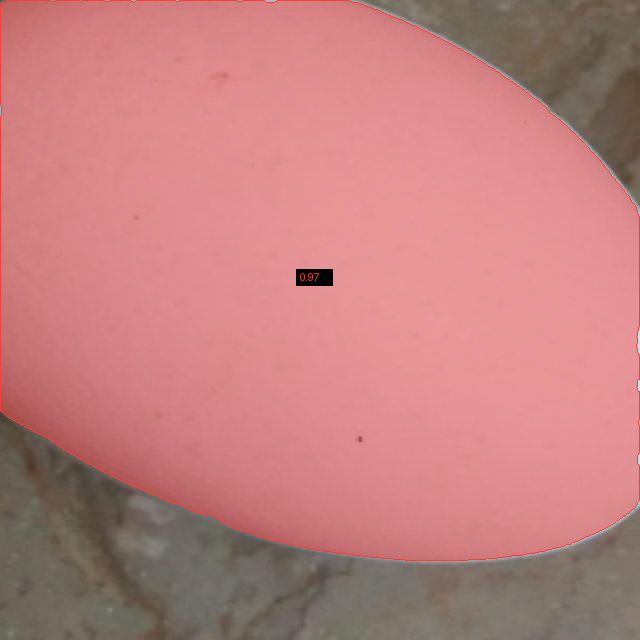

In [6]:
from IPython.display import display

image_paths = all_images
sample_path = image_paths[0]

image, masks, scores, kept, n_raw = segment_image(sample_path)

print("Image:", sample_path.name)
print("Raw detections:", n_raw)
print("Masks after duplicate removal:", len(kept))
print("Confidence scores:", [round(float(scores[i]), 3) for i in kept])

display(image)
display(make_overlay(image, masks, scores, kept))

# Process every image and save the results

In [7]:
import csv
import time
from collections import deque
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from PIL import Image
import numpy as np
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

DATA_DIR = dataset_dir
OUT_DIR = Path("/content/task1_outputs")

MASK_DIR = OUT_DIR / "sam_masks"
UNION_DIR = OUT_DIR / "union_masks"
OVERLAY_DIR = OUT_DIR / "sam_overlays"
REPORT_PATH = OUT_DIR / "sam_report.csv"

for folder in (MASK_DIR, UNION_DIR, OVERLAY_DIR):
    folder.mkdir(parents=True, exist_ok=True)

fields = [
    "image", "split", "n_raw", "n_eggs",
    "scores", "areas", "flags", "seconds",
]

def get_split(path):
    for part in path.parts:
        if part in {"train", "test", "valid"}:
            return part
    return "unknown"

# Load existing CSV records into a dict keyed by image path (prevents duplicate rows on resume)
records = {}
if REPORT_PATH.exists() and REPORT_PATH.stat().st_size > 0:
    with REPORT_PATH.open("r", newline="") as f:
        for row in csv.DictReader(f):
            records[row["image"]] = row

# Identify images that still need processing
pending_paths = []
for path in image_paths:
    rel = path.relative_to(DATA_DIR)
    key = rel.as_posix()
    mask_path = (MASK_DIR / rel).with_suffix(".png")
    union_path = (UNION_DIR / rel).with_suffix(".png")
    overlay_path = (OVERLAY_DIR / rel).with_suffix(".jpg")

    if not (
        key in records
        and mask_path.exists()
        and union_path.exists()
        and overlay_path.exists()
    ):
        pending_paths.append(path)

print(f"Already completed: {len(image_paths) - len(pending_paths)} | Remaining: {len(pending_paths)}")


class ImagePrefetchDataset(Dataset):
    """Decouples disk read and PIL RGB decoding from the main GPU loop."""
    def __init__(self, paths):
        self.paths = paths

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        path = self.paths[idx]
        with Image.open(path) as img:
            rgb = img.convert("RGB")
        return path, rgb


def save_artifacts(labels, union, overlay_pil, mask_path, union_path, overlay_path):
    """Background thread worker to write PNG/JPEG outputs without stalling the GPU."""
    for p in (mask_path, union_path, overlay_path):
        p.parent.mkdir(parents=True, exist_ok=True)
    Image.fromarray(labels).save(mask_path)
    Image.fromarray(union).save(union_path)
    overlay_pil.save(overlay_path, quality=90)


if pending_paths:
    loader = DataLoader(
        ImagePrefetchDataset(pending_paths),
        batch_size=1,
        shuffle=False,
        num_workers=2,
        collate_fn=lambda batch: batch[0],
    )

    # Rewrite header + existing valid records cleanly before appending new ones
    with REPORT_PATH.open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fields)
        writer.writeheader()
        for row in records.values():
            writer.writerow(row)

    pending_futures = deque()
    MAX_PENDING_WRITES = 8

    with ThreadPoolExecutor(max_workers=2) as io_pool, REPORT_PATH.open("a", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fields)

        for path, image in tqdm(loader, total=len(pending_paths), desc="SAM 3 Inference"):
            start = time.time()
            rel = path.relative_to(DATA_DIR)
            key = rel.as_posix()

            mask_path = (MASK_DIR / rel).with_suffix(".png")
            union_path = (UNION_DIR / rel).with_suffix(".png")
            overlay_path = (OVERLAY_DIR / rel).with_suffix(".jpg")

            _, masks, scores, kept, n_raw = segment_image(image)

            width, height = image.size
            labels = np.zeros((height, width), dtype=np.uint16)

            # Paint in reverse order so higher-confidence masks (lower index) overwrite lower-confidence ones on overlap,
            # while keeping label_id (1, 2, ...) strictly aligned with the CSV score/area ordering.
            for idx in reversed(kept):
                label_id = idx + 1
                labels[masks[idx]] = label_id

            union = (labels > 0).astype(np.uint8) * 255
            overlay_pil = make_overlay(image, masks, scores, kept)

            # Submit disk writes to background thread & bound queue size to prevent RAM buildup
            pending_futures.append(
                io_pool.submit(
                    save_artifacts, labels, union, overlay_pil, mask_path, union_path, overlay_path
                )
            )
            if len(pending_futures) >= MAX_PENDING_WRITES:
                pending_futures.popleft().result()  # Surfaces any disk errors immediately

            areas = [float(masks[i].mean()) for i in kept]
            selected_scores = [float(scores[i]) for i in kept]

            flags = []
            if not kept:
                flags.append("NO_DETECTION")
            if len(kept) > 1:
                flags.append("MULTI_EGG")
            if any(s < 0.5 for s in selected_scores):
                flags.append("LOW_SCORE")
            if any(a > 0.90 for a in areas):
                flags.append("VERY_LARGE_MASK")

            row = {
                "image": key,
                "split": get_split(path),
                "n_raw": n_raw,
                "n_eggs": len(kept),
                "scores": ";".join(f"{s:.3f}" for s in selected_scores),
                "areas": ";".join(f"{a:.4f}" for a in areas),
                "flags": "|".join(flags),
                "seconds": f"{time.time() - start:.2f}",
            }
            records[key] = row
            writer.writerow(row)
            f.flush()

        # Drain remaining background writes
        while pending_futures:
            pending_futures.popleft().result()

print("\nTask 1 inference finished.")
print("Saved outputs:", OUT_DIR)

Already completed: 0 | Remaining: 160


SAM 3 Inference:   0%|          | 0/160 [00:00<?, ?it/s]


Task 1 inference finished.
Saved outputs: /content/task1_outputs


# Review the overlays and failures

=== Pipeline QA Summary (160 images, avg 3.03s/img) ===
  • CLEAN_SINGLE_EGG  :  126 (78.8%)
  • MULTI_EGG         :   22 (13.8%)
  • NO_DETECTION      :   10 (6.2%)
  • LOW_SCORE         :    3 (1.9%)
  • VERY_LARGE_MASK   :    1 (0.6%)


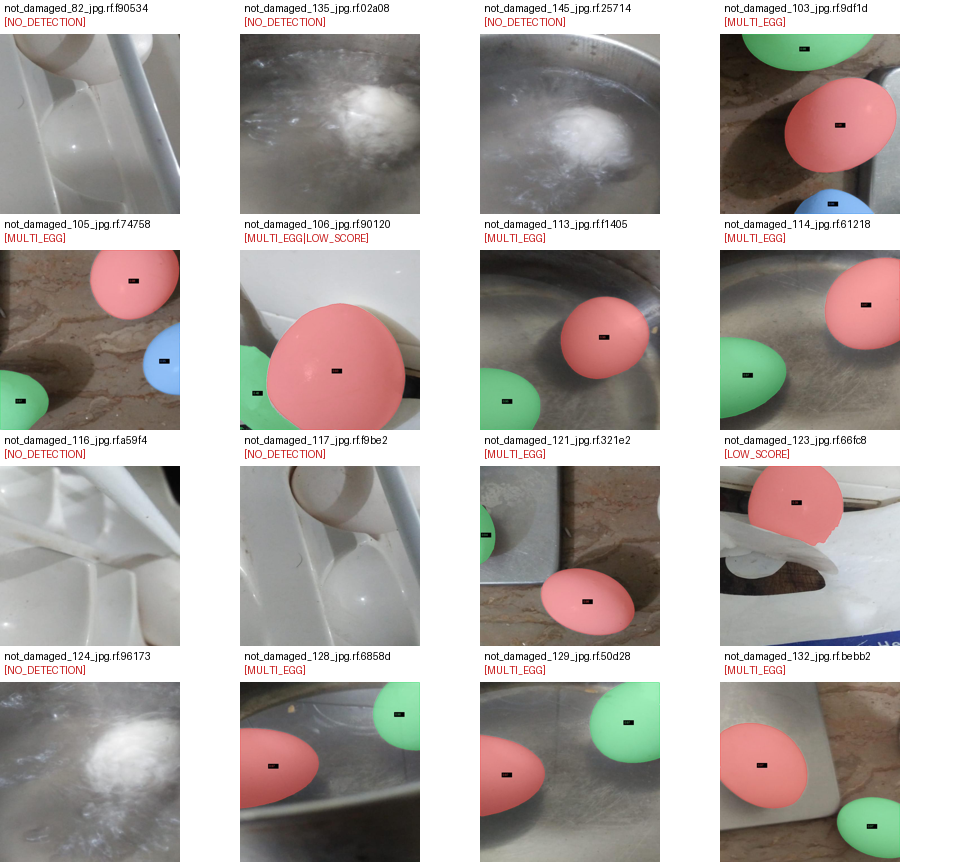

In [8]:
from collections import Counter
from PIL import Image, ImageDraw
from IPython.display import display
import math

with REPORT_PATH.open(newline="") as f:
    rows = list(csv.DictReader(f))

total_imgs = len(rows)
flag_counts = Counter()
for r in rows:
    if r["flags"]:
        for fl in r["flags"].split("|"):
            flag_counts[fl] += 1
    else:
        flag_counts["CLEAN_SINGLE_EGG"] += 1

avg_time = np.mean([float(r["seconds"]) for r in rows]) if rows else 0.0

print(f"=== Pipeline QA Summary ({total_imgs} images, avg {avg_time:.2f}s/img) ===")
for k, v in flag_counts.most_common():
    print(f"  • {k:<18}: {v:>4} ({100.0 * v / max(1, total_imgs):.1f}%)")

# Prioritize flagged images in the visual contact sheet so edge cases are inspected first
flagged_rows = [r for r in rows if r["flags"]]
clean_rows = [r for r in rows if not r["flags"]]
sample_rows = (flagged_rows + clean_rows)[:16]

cols = 4
thumb_w, thumb_h = 240, 180
cell_h = thumb_h + 36
sheet = Image.new(
    "RGB",
    (cols * thumb_w, max(1, math.ceil(len(sample_rows) / cols)) * cell_h),
    "white",
)
draw = ImageDraw.Draw(sheet)

for i, r in enumerate(sample_rows):
    overlay_path = (OVERLAY_DIR / r["image"]).with_suffix(".jpg")
    if not overlay_path.exists():
        continue

    thumb = Image.open(overlay_path).convert("RGB")
    thumb.thumbnail((thumb_w, thumb_h))

    x = (i % cols) * thumb_w
    y = (i // cols) * cell_h

    status = r["flags"] if r["flags"] else "OK"
    header_color = (200, 30, 30) if r["flags"] else (20, 130, 40)

    draw.text((x + 4, y + 2), Path(r["image"]).name[:28], fill="black")
    draw.text((x + 4, y + 16), f"[{status[:28]}]", fill=header_color)
    sheet.paste(thumb, (x, y + 34))

display(sheet)

# Download Output

In [9]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/task1_outputs",
    "zip",
    root_dir=OUT_DIR,
)

print("Archive created:", zip_path)
files.download(zip_path)

Archive created: /content/task1_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>